<a href="https://colab.research.google.com/github/asmipandey18/Elevvo_Ml_Internship/blob/main/Student_score_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Task 1 : Student Score Prediction


In [ ]:
## import libraries
import pandas as pd

In [ ]:
df = pd.read_csv("/content/StudentPerformanceFactors.csv")

In [ ]:
df.head(10)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
5,19,88,Medium,Medium,Yes,8,89,Medium,Yes,3,Medium,Medium,Public,Positive,3,No,Postgraduate,Near,Male,71
6,29,84,Medium,Low,Yes,7,68,Low,Yes,1,Low,Medium,Private,Neutral,2,No,High School,Moderate,Male,67
7,25,78,Low,High,Yes,6,50,Medium,Yes,1,High,High,Public,Negative,2,No,High School,Far,Male,66
8,17,94,Medium,High,No,6,80,High,Yes,0,Medium,Low,Private,Neutral,1,No,College,Near,Male,69
9,23,98,Medium,Medium,Yes,8,71,Medium,Yes,0,High,High,Public,Positive,5,No,High School,Moderate,Male,72


In [ ]:
df.shape

(6607, 20)

## Data cleaning

In [ ]:
# 1. Check dataset information
print("Dataset Information:")
df.info()

# 2. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 4. Display statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))

# 5. Remove duplicate rows
df = df.drop_duplicates()

# 6. Display final dataset shape
print("\nDataset shape after removing duplicates:", df.shape)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence             

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
count,6607.000000,6607.000000,6607,6607,6607,6607.00000,6607.000000,6607,6607,6607.000000,6607,6529,6607,6607,6607.000000,6607,6517,6540,6607,6607.000000
unique,NaN,NaN,3,3,2,NaN,NaN,3,2,NaN,3,3,2,3,NaN,2,3,3,2,NaN
top,NaN,NaN,Medium,Medium,Yes,NaN,NaN,Medium,Yes,NaN,Low,Medium,Public,Positive,NaN,No,High School,Near,Male,NaN
freq,NaN,NaN,3362,3319,3938,NaN,NaN,3351,6108,NaN,2672,3925,4598,2638,NaN,5912,3223,3884,3814,NaN
mean,19.975329,79.977448,NaN,NaN,NaN,7.02906,75.070531,NaN,NaN,1.493719,NaN,NaN,NaN,NaN,2.967610,NaN,NaN,NaN,NaN,67.235659
std,5.990594,11.547475,NaN,NaN,NaN,1.46812,14.399784,NaN,NaN,1.230570,NaN,NaN,NaN,NaN,1.031231,NaN,NaN,NaN,NaN,3.890456
min,1.000000,60.000000,NaN,NaN,NaN,4.00000,50.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,55.000000
25%,16.000000,70.000000,NaN,NaN,NaN,6.00000,63.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,65.000000
50%,20.000000,80.000000,NaN,NaN,NaN,7.00000,75.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,3.000000,NaN,NaN,NaN,NaN,67.000000
75%,24.000000,90.000000,NaN,NaN,NaN,8.00000,88.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,69.000000



Dataset shape after removing duplicates: (6607, 20)


In [ ]:
# Fill missing values using the most frequent category
columns_to_fill = [
    "Teacher_Quality",
    "Parental_Education_Level",
    "Distance_from_Home"
]

for col in columns_to_fill:
    df[col] = df[col].fillna(df[col].mode()[0])

# Verify the cleaning
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Dataset shape:", df.shape)

Total missing values: 0
Duplicate rows: 0
Dataset shape: (6607, 20)


In [63]:

# Check for exam scores outside the expected 0–100 range

print("Scores above 100:", (df["Exam_Score"] > 100).sum())
print("Scores below 0:", (df["Exam_Score"] < 0).sum())

# Display any scores above 100
print("\nRows with exam scores above 100:")
display(df[df["Exam_Score"] > 100])


Scores above 100: 1
Scores below 0: 0

Rows with exam scores above 100:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101


In [64]:

# Remove rows where Exam_Score is outside the valid 0–100 range
df = df[df["Exam_Score"].between(0, 100)].copy()

# Check the updated dataset
print("Updated dataset shape:", df.shape)
print("Scores above 100:", (df["Exam_Score"] > 100).sum())
print("Scores below 0:", (df["Exam_Score"] < 0).sum())


Updated dataset shape: (6606, 20)
Scores above 100: 0
Scores below 0: 0


## Data Visualization

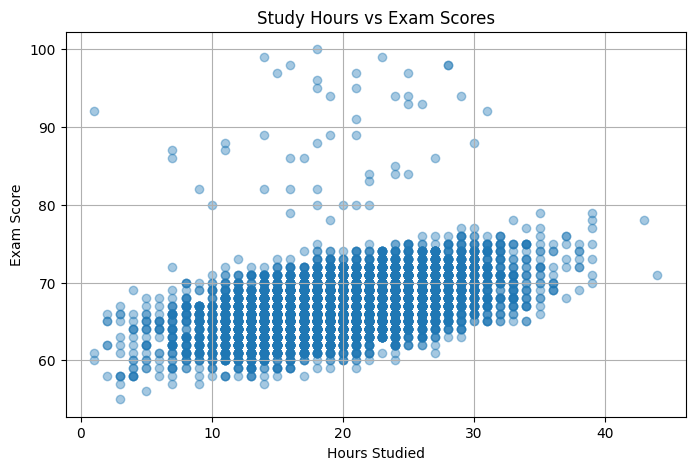

In [65]:
## 1. Study Hours vs Exam Scores
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Hours_Studied"],
    df["Exam_Score"],
    alpha=0.4
)

plt.title("Study Hours vs Exam Scores")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.grid(True)

plt.show()

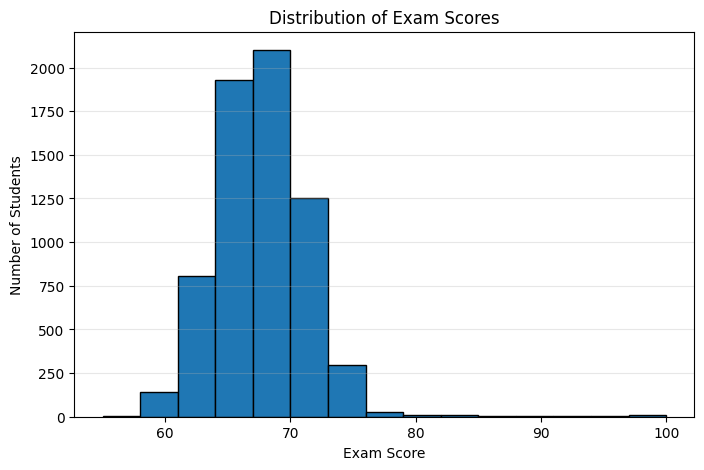

In [66]:
## 2. Exam Score Distribution
plt.figure(figsize=(8, 5))

plt.hist(df["Exam_Score"], bins=15, edgecolor="black")

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.grid(axis="y", alpha=0.3)

plt.show()

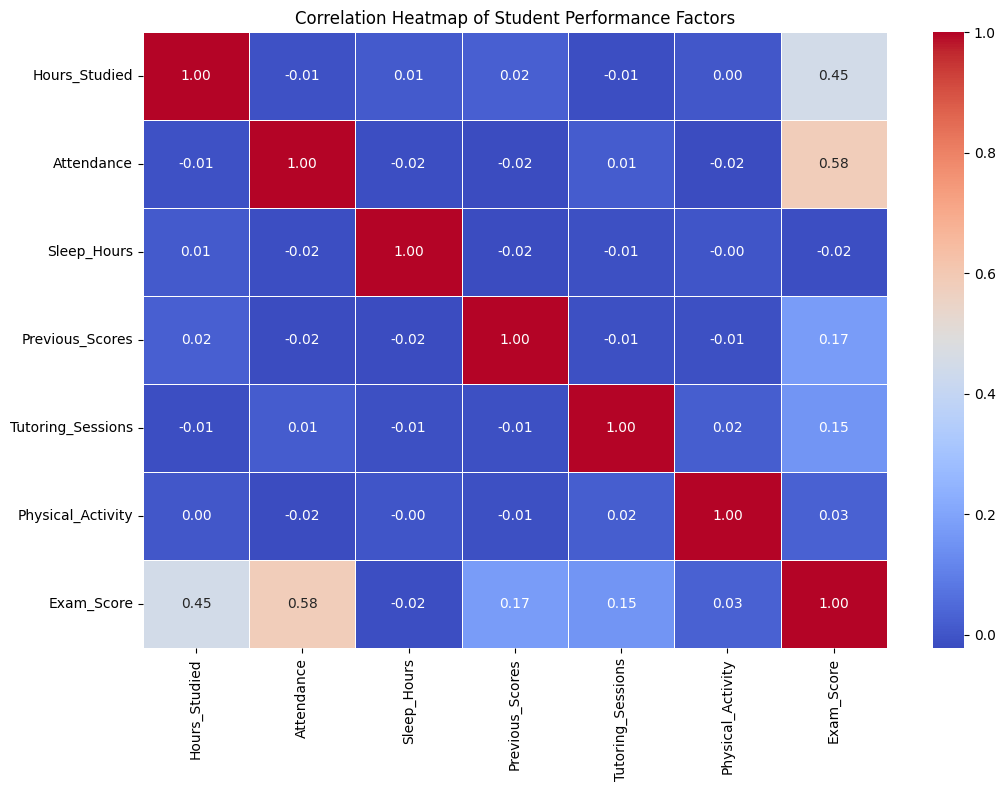

In [67]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns only
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
correlation = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Student Performance Factors")
plt.show()

In [68]:
## Separate input and output
# Input feature: hours studied
X = df[["Hours_Studied"]]

# Target variable: exam score
y = df["Exam_Score"]

# Check the data
print("Input shape:", X.shape)
print("Target shape:", y.shape)

print(X.head())
print(y.head())

Input shape: (6606, 1)
Target shape: (6606,)
   Hours_Studied
0             23
1             19
2             24
3             29
4             19
0    67
1    61
2    74
3    71
4    70
Name: Exam_Score, dtype: int64


## Split the dataset

In [69]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

## Train the model


In [70]:
from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
model = LinearRegression()

# Train the model using training data
model.fit(X_train, y_train)


LinearRegression()

In [71]:
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Coefficient: 0.28571318331248846
Intercept: 61.54600994601386


In [72]:
# Predict exam scores using the test data
y_pred = model.predict(X_test)

# Display actual and predicted scores
print("Actual exam scores:")
print(y_test.head(10).to_list())

print("\nPredicted exam scores:")
print(y_pred[:10].round(2))

Actual exam scores:
[66, 66, 67, 67, 68, 63, 74, 65, 69, 76]

Predicted exam scores:
[66.12 65.83 68.69 64.69 67.55 64.69 70.4  64.12 66.12 69.83]


## Evaluate model performance

In [73]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("Model Evaluation Results")
print("-------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))

Model Evaluation Results
-------------------------
MAE: 2.42
MSE: 9.96
RMSE: 3.16
R² Score: 0.2469


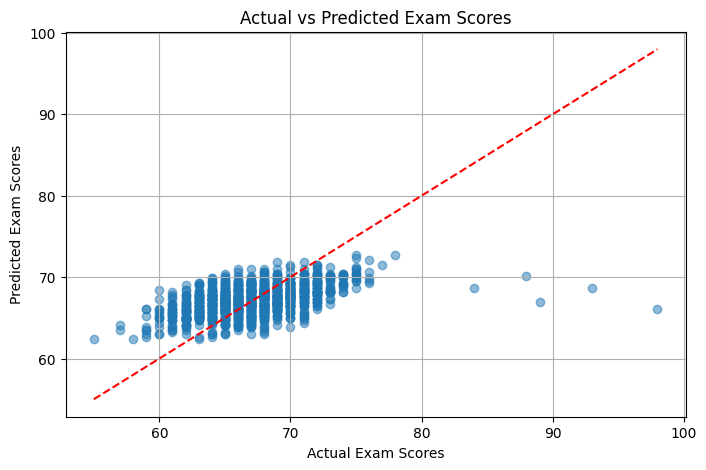

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")
plt.title("Actual vs Predicted Exam Scores")
plt.grid(True)
plt.show()

## Bonus
Create the Polynomial Regression model

In [75]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

In [76]:
# Create Polynomial Regression model with degree 2
poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

# Train the model using the same training data
poly_model.fit(X_train, y_train)


Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(include_bias=False)),
                ('linearregression', LinearRegression())])

In [77]:

# Predict exam scores using Polynomial Regression
y_poly_pred = poly_model.predict(X_test)

# Calculate evaluation metrics
poly_mae = mean_absolute_error(y_test, y_poly_pred)
poly_mse = mean_squared_error(y_test, y_poly_pred)
poly_rmse = np.sqrt(poly_mse)
poly_r2 = r2_score(y_test, y_poly_pred)

# Display results
print("Polynomial Regression Results")
print("------------------------------")
print("MAE:", round(poly_mae, 2))
print("MSE:", round(poly_mse, 2))
print("RMSE:", round(poly_rmse, 2))
print("R² Score:", round(poly_r2, 4))


Polynomial Regression Results
------------------------------
MAE: 2.42
MSE: 9.95
RMSE: 3.15
R² Score: 0.2479


### Polynomial Regression Results

Polynomial Regression achieved an R² score of 0.2479, compared with 0.2469 for standard Linear Regression. This very small improvement suggests that adding a quadratic term did not meaningfully improve predictions, although it does not prove that the relationship is entirely linear.

## Compare Linear Regression vs Polynomial Regression

In [78]:
comparison = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R² Score"],
    "Linear Regression": [
        mae,
        mse,
        rmse,
        r2
    ],
    "Polynomial Regression": [
        poly_mae,
        poly_mse,
        poly_rmse,
        poly_r2
    ]
})

print(comparison.round(4).to_string(index=False))


  Metric  Linear Regression  Polynomial Regression
     MAE             2.4190                 2.4151
     MSE             9.9598                 9.9464
    RMSE             3.1559                 3.1538
R² Score             0.2469                 0.2479


## Feature Combination Experiment

In [79]:
# Select multiple numerical features
X_multi = df[
    [
        "Hours_Studied",
        "Attendance",
        "Sleep_Hours",
        "Previous_Scores",
        "Tutoring_Sessions",
        "Physical_Activity"
    ]
]

# Target variable
y = df["Exam_Score"]


In [80]:
X_multi_train, X_multi_test, y_multi_train, y_multi_test = train_test_split(
    X_multi, y, test_size=0.2, random_state=42
)

# Train the multiple-feature Linear Regression model
multi_model = LinearRegression()
multi_model.fit(X_multi_train, y_multi_train)


LinearRegression()

In [81]:
# Make predictions
y_multi_pred = multi_model.predict(X_multi_test)

In [82]:
# Evaluate the model
multi_mae = mean_absolute_error(y_multi_test, y_multi_pred)
multi_mse = mean_squared_error(y_multi_test, y_multi_pred)
multi_rmse = np.sqrt(multi_mse)
multi_r2 = r2_score(y_multi_test, y_multi_pred)

print("Multiple-Feature Linear Regression Results")
print("------------------------------------------")
print("MAE:", round(multi_mae, 4))
print("MSE:", round(multi_mse, 4))
print("RMSE:", round(multi_rmse, 4))
print("R² Score:", round(multi_r2, 4))


Multiple-Feature Linear Regression Results
------------------------------------------
MAE: 1.2442
MSE: 4.1746
RMSE: 2.0432
R² Score: 0.6843


## Test three additional feature combinations

In [83]:
# Define the target
y = df["Exam_Score"]

# Three additional feature combinations
feature_sets = {
    "Study + Attendance": ["Hours_Studied", "Attendance"],
    "Study + Sleep": ["Hours_Studied", "Sleep_Hours"],
    "Academic Features": [
        "Hours_Studied", "Attendance", "Previous_Scores"
    ]
}

results = []

for name, features in feature_sets.items():
    X_combo = df[features]

    # Use the same split settings for a fair comparison
    X_train_combo, X_test_combo, y_train_combo, y_test_combo = train_test_split(
        X_combo, y, test_size=0.2, random_state=42
    )

    # Train and predict
    combo_model = LinearRegression()
    combo_model.fit(X_train_combo, y_train_combo)
    y_pred_combo = combo_model.predict(X_test_combo)

    # Evaluate
    results.append({
        "Feature Combination": name,
        "MAE": mean_absolute_error(y_test_combo, y_pred_combo),
        "MSE": mean_squared_error(y_test_combo, y_pred_combo),
        "RMSE": np.sqrt(mean_squared_error(y_test_combo, y_pred_combo)),
        "R² Score": r2_score(y_test_combo, y_pred_combo)
    })

# Display the comparison table
feature_results = pd.DataFrame(results)
print(feature_results.round(4).to_string(index=False))


Feature Combination    MAE    MSE   RMSE  R² Score
 Study + Attendance 1.4302 5.0028 2.2367    0.6217
      Study + Sleep 2.4218 9.9641 3.1566    0.2465
  Academic Features 1.3296 4.5564 2.1346    0.6554


### Feature Combination Results

The Study + Sleep model achieved an R² score of 0.2465, slightly lower than the 0.2469 score obtained using study hours alone. This suggests that adding sleep hours to study hours did not improve predictive performance in this experiment. Testing sleep alongside other relevant features may provide further insight.

## Compare all Four models

In [91]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression",
        "Multiple-Feature Linear Regression",
        "Academic Features"
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, y_poly_pred),
        mean_absolute_error(y_multi_test, y_multi_pred),
        1.3296
    ],
    "MSE": [
        mean_squared_error(y_test, y_pred),
        mean_squared_error(y_test, y_poly_pred),
        mean_squared_error(y_multi_test, y_multi_pred),
        4.5564
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, y_poly_pred)),
        np.sqrt(mean_squared_error(y_multi_test, y_multi_pred)),
        2.1346
    ],
    "R² Score": [
        r2_score(y_test, y_pred),
        r2_score(y_test, y_poly_pred),
        r2_score(y_multi_test, y_multi_pred),
        0.6554
    ]
})

display(comparison.round(4))


,Model,MAE,MSE,RMSE,R² Score
0,Linear Regression,2.4190,9.9598,3.1559,0.2469
1,Polynomial Regression,2.4151,9.9464,3.1538,0.2479
2,Multiple-Feature Linear Regression,1.2442,4.1746,2.0432,0.6843
3,Academic Features,1.3296,4.5564,2.1346,0.6554


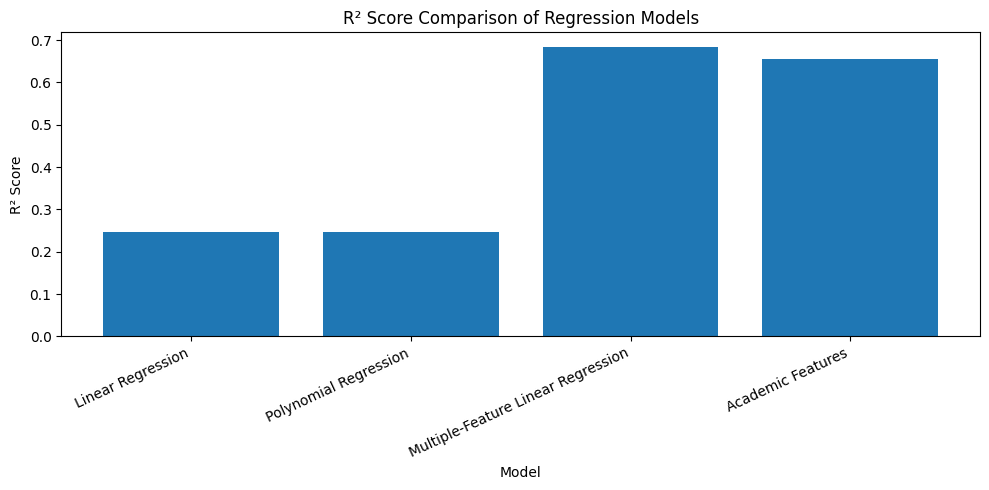

In [92]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(comparison["Model"], comparison["R² Score"])

plt.title("R² Score Comparison of Regression Models")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.show()


## Conclusion

In this project, I developed regression models to predict student exam scores using the Student Performance Factors dataset. I cleaned the dataset, handled missing values, checked for duplicate records and invalid exam scores, and explored relationships between student features and exam scores using visualizations.

I trained and evaluated Linear Regression, Polynomial Regression, and Multiple-Feature Linear Regression models. I also tested different feature combinations to understand how the selection of input features affects prediction performance. Polynomial Regression improved the R² score only slightly, from 0.2469 to 0.2479, while the Study + Sleep combination did not improve performance over study hours alone.

The Multiple-Feature Linear Regression model performed best among the four models, achieving an R² score of 0.6843, an MAE of 1.2442, and an RMSE of 2.0432. In comparison, the model using study hours alone achieved an R² score of 0.2469, suggesting that other features provide important predictive information.

**Limitations and Future Work:** The study-hours-only model has relatively low predictive performance, and the models tested so far use numerical features only. Future work could include categorical features such as parental involvement, access to resources, and motivation level, using suitable encoding techniques. Testing additional models and validating their performance on different data splits could also help improve reliability.

Overall, this project helped me understand data cleaning, exploratory data analysis, feature selection, train-test splitting, regression modeling, model evaluation, and visualization using Python, Pandas, Matplotlib, and Scikit-learn.